# Retail Case Study 고객 구매 패턴 분석과 RFM 고객 세분화

상품·고객·거래 데이터를 연결해 구매 패턴을 탐색하고 RFM으로 고객을 세분화한다. 전처리와 통계 로직은 `src/pipeline.py`의 `DataAnalyzer`에서 호출한다.

로컬에서 같은 분석을 실행하는 방법은 [README](../README.md)에 정리했다.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.pipeline import DataAnalyzer

DATA_DIR = Path(os.environ.get("RETAIL_DATA_DIR", PROJECT_ROOT / "data"))
RANDOM_SEED = 42
analyzer = DataAnalyzer(DATA_DIR)

## 1. 데이터 로드 및 기본 탐색

- `Transactions.csv`는 거래일, 고객 ID, 상품 서브카테고리 코드, 카테고리 코드, 수량, 단가, 세금, 거래 금액을 제공한다.
- `Customer.csv`는 고객 생년월일, 성별, 도시 코드를 제공한다.
- `prod_cat_info.csv`는 상품 카테고리명과 서브카테고리명을 제공한다.

거래 이력이 있는 고객 ID를 정렬한 뒤 고정 시드로 300명을 뽑고, 선택된 고객의 관측 기간 거래를 모두 보존한다.
반품에 해당하는 음수 거래 금액은 분석에서 제외한다.

In [2]:
transactions, customers, products = analyzer.load_data(
    sample_size=300, random_state=RANDOM_SEED
)
assert len(transactions) >= 1_000, "표본 거래가 1,000행 이상 필요합니다."

print("거래 표본:", transactions.shape)
print("고객 표본:", customers.shape)
print("상품 표본:", products.shape)

for table in (transactions, customers, products):
    display(table.head())
    table.info()

거래 표본: (1188, 10)
고객 표본: (300, 5)
상품 표본: (23, 4)


,transaction_id,customer_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type
36,32130400636,269772,2014-02-19,12,6,3,229,72.135,759.135,e-Shop
40,90740728864,268229,2014-02-19,4,2,5,984,516.600,5436.600,TeleShop
45,67079812295,271818,2014-02-19,10,3,2,1408,295.680,3111.680,MBR
75,75980673312,270678,2014-02-17,7,5,4,1377,578.340,6086.340,TeleShop
80,55452156634,273734,2014-02-16,3,5,5,778,408.450,4298.450,e-Shop


<class 'pandas.core.frame.DataFrame'>
Index: 1188 entries, 36 to 23008
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    1188 non-null   int64         
 1   customer_id       1188 non-null   string        
 2   tran_date         1188 non-null   datetime64[ns]
 3   prod_subcat_code  1188 non-null   string        
 4   prod_cat_code     1188 non-null   string        
 5   Qty               1188 non-null   int64         
 6   Rate              1188 non-null   int64         
 7   Tax               1188 non-null   float64       
 8   total_amt         1188 non-null   float64       
 9   Store_type        1188 non-null   object        
dtypes: datetime64[ns](1), float64(2), int64(3), object(1), string(3)
memory usage: 102.1+ KB


,customer_id,DOB,Gender,city_code,age
40,271777,1970-03-08,M,8.0,44.0
45,272821,1970-03-17,F,3.0,43.9
70,275250,1970-05-02,F,1.0,43.8
77,269271,1970-05-12,F,5.0,43.8
79,267386,1970-05-15,M,7.0,43.8


<class 'pandas.core.frame.DataFrame'>
Index: 300 entries, 40 to 5604
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   customer_id  300 non-null    string        
 1   DOB          300 non-null    datetime64[ns]
 2   Gender       300 non-null    object        
 3   city_code    300 non-null    float64       
 4   age          300 non-null    float64       
dtypes: datetime64[ns](1), float64(2), object(1), string(1)
memory usage: 14.1+ KB


,prod_cat_code,prod_cat,prod_subcat_code,prod_subcat
0,1,Clothing,4,Mens
1,1,Clothing,1,Women
2,1,Clothing,3,Kids
3,2,Footwear,1,Mens
4,2,Footwear,3,Women


<class 'pandas.core.frame.DataFrame'>
Index: 23 entries, 0 to 22
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   prod_cat_code     23 non-null     string
 1   prod_cat          23 non-null     object
 2   prod_subcat_code  23 non-null     string
 3   prod_subcat       23 non-null     object
dtypes: object(2), string(2)
memory usage: 920.0+ bytes


## 2. 결측치 처리와 데이터 병합

성별(`Gender`)이 비어 있으면 `Unknown`으로 표시한다. 고객 나이는 생년월일(`DOB`)에서 기준일 기준으로 계산하며, 생년월일이 없는 경우 성별 그룹의 중앙값으로 대치하고 남은 값에는 전체 중앙값을 사용한다.

거래를 기준으로 상품과 고객 정보를 연결한다.

In [3]:
display(products.isna().sum())
display(customers.isna().sum())
display(transactions.isna().sum())

prod_cat_code       0
prod_cat            0
prod_subcat_code    0
prod_subcat         0
dtype: int64

customer_id    0
DOB            0
Gender         0
city_code      0
age            0
dtype: int64

transaction_id      0
customer_id         0
tran_date           0
prod_subcat_code    0
prod_cat_code       0
Qty                 0
Rate                0
Tax                 0
total_amt           0
Store_type          0
dtype: int64

In [4]:
customers["Gender"] = customers["Gender"].fillna("Unknown")
customers["age"] = analyzer.handle_missing_values(
    customers, "age", group_col="Gender", strategy="median"
)

customers.isna().sum()

customer_id    0
DOB            0
Gender         0
city_code      0
age            0
dtype: int64

In [5]:
df = transactions.merge(
    products,
    left_on=["prod_cat_code", "prod_subcat_code"],
    right_on=["prod_cat_code", "prod_subcat_code"],
    how="left",
)

df = df.merge(
    customers,
    on="customer_id",
    how="left",
)

print(df.shape)
display(df.head())

df.isna().sum()

(1188, 16)


,transaction_id,customer_id,tran_date,prod_subcat_code,prod_cat_code,Qty,Rate,Tax,total_amt,Store_type,prod_cat,prod_subcat,DOB,Gender,city_code,age
0,32130400636,269772,2014-02-19,12,6,3,229,72.135,759.135,e-Shop,Home and kitchen,Tools,1981-05-25,F,9.0,32.7
1,90740728864,268229,2014-02-19,4,2,5,984,516.600,5436.600,TeleShop,Footwear,Kids,1989-03-01,F,3.0,25.0
2,67079812295,271818,2014-02-19,10,3,2,1408,295.680,3111.680,MBR,Electronics,Audio and video,1973-04-03,M,7.0,40.9
3,75980673312,270678,2014-02-17,7,5,4,1377,578.340,6086.340,TeleShop,Books,Fiction,1970-08-06,F,4.0,43.5
4,55452156634,273734,2014-02-16,3,5,5,778,408.450,4298.450,e-Shop,Books,Comics,1987-11-07,F,9.0,26.3


transaction_id      0
customer_id         0
tran_date           0
prod_subcat_code    0
prod_cat_code       0
Qty                 0
Rate                0
Tax                 0
total_amt           0
Store_type          0
prod_cat            0
prod_subcat         0
DOB                 0
Gender              0
city_code           0
age                 0
dtype: int64

## 3. 텍스트 피처 생성

서브카테고리명(`prod_subcat`)의 문자 수를 계산해 `product_name_length` 컬럼을 추가한다.
공백과 숫자, 특수문자도 문자 수에 포함한다.

In [6]:
df = analyzer.add_text_features(df)

display(
    df[["prod_subcat_code", "prod_subcat", "product_name_length"]].head()
)

,prod_subcat_code,prod_subcat,product_name_length
0,12,Tools,5
1,4,Kids,4
2,10,Audio and video,15
3,7,Fiction,7
4,3,Comics,6


In [7]:
display(
    df.drop_duplicates("prod_subcat_code")["product_name_length"].describe()
)

count    12.000000
mean      8.083333
std       4.737823
min       3.000000
25%       4.750000
50%       7.000000
75%       9.250000
max      19.000000
Name: product_name_length, dtype: float64

## 4. IQR 기반 거래 금액 이상치 탐지

IQR은 제3사분위수(Q3)와 제1사분위수(Q1)의 차이다.

- 하한: Q1 - 1.5 × IQR
- 상한: Q3 + 1.5 × IQR

범위 밖의 거래 금액을 이상치 후보로 표시한다.
고가 구매도 정상 거래일 수 있으므로 거래를 삭제하지 않고,
이상치 후보를 제외했을 때의 분포를 비교한다.

In [8]:
df["amount_outlier"] = analyzer.detect_outliers(df["total_amt"], threshold=1.5)

print("전체 거래 수:", len(df))
print("이상치 후보 수:", df["amount_outlier"].sum())
print(
    "이상치 후보 비율:",
    round(df["amount_outlier"].mean() * 100, 2),
    "%",
)

전체 거래 수: 1188
이상치 후보 수: 18
이상치 후보 비율: 1.52 %


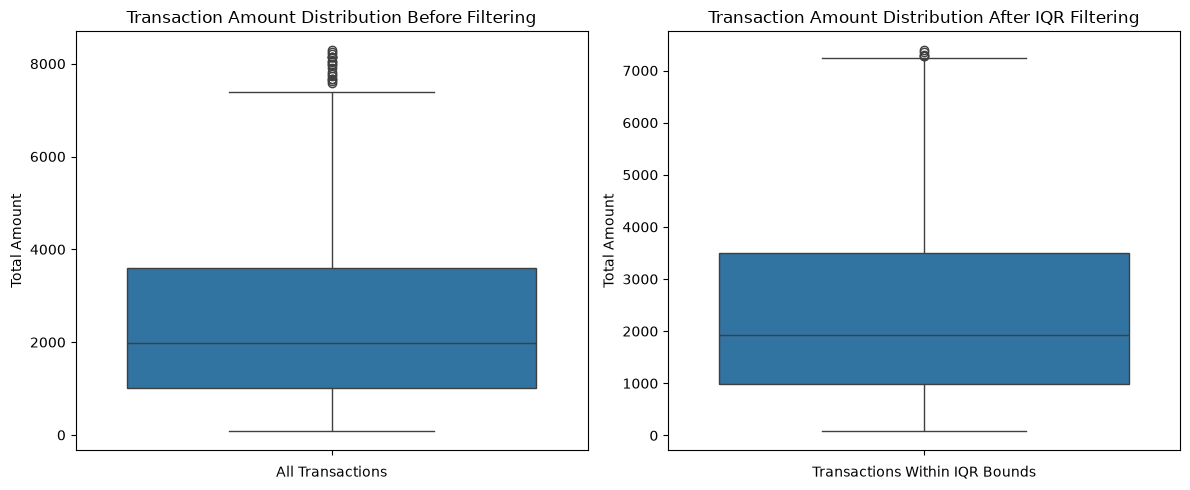

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["total_amt"], ax=axes[0])
axes[0].set_title("Transaction Amount Distribution Before Filtering")
axes[0].set_xlabel("All Transactions")
axes[0].set_ylabel("Total Amount")

sns.boxplot(
    y=df.loc[~df["amount_outlier"], "total_amt"],
    ax=axes[1],
)
axes[1].set_title("Transaction Amount Distribution After IQR Filtering")
axes[1].set_xlabel("Transactions Within IQR Bounds")
axes[1].set_ylabel("Total Amount")

plt.tight_layout()
plt.show()

## 5. 이미지 피처 생성

`data/images/{prod_cat_code}/{prod_subcat_code}.jpg` 경로에 저장된 카테고리별 상품 이미지를 읽고 픽셀 통계를 추출한다.

- `image_mean`: 전체 픽셀 값의 평균 (0–1로 정규화)
- `image_std`: 전체 픽셀 값의 표준편차

파일 I/O는 상품마다 순회하되, 픽셀 통계 계산은 `np.mean(pixels)` / `np.std(pixels)` NumPy 벡터 연산으로 처리해 Python for loop을 사용하지 않는다.
이미지가 없는 상품은 결측치로 유지한다.

In [10]:
products = analyzer.add_image_features(products)

print("이미지 처리 완료")
print("이미지 피처 결측 상품 수:", products["image_mean"].isna().sum())
display(products[["prod_subcat_code", "prod_subcat", "image_mean", "image_std"]].head())

이미지 처리 완료
이미지 피처 결측 상품 수: 0


,prod_subcat_code,prod_subcat,image_mean,image_std
0,4,Mens,0.610569,0.210978
1,1,Women,0.523323,0.206854
2,3,Kids,0.582972,0.209238
3,1,Mens,0.401521,0.162987
4,3,Women,0.461122,0.166765


In [11]:

# prod_subcat_code는 카테고리마다 중복되므로 (cat_code, subcat_code) 복합 키로 매핑한다
image_lookup = products.copy()
image_lookup["_key"] = image_lookup["prod_cat_code"] + "_" + image_lookup["prod_subcat_code"]
image_lookup = image_lookup.set_index("_key")[["image_mean", "image_std"]]

df["_key"] = df["prod_cat_code"] + "_" + df["prod_subcat_code"]
df["image_mean"] = df["_key"].map(image_lookup["image_mean"])
df["image_std"] = df["_key"].map(image_lookup["image_std"])
df = df.drop(columns=["_key"])

display(df[["prod_subcat_code", "image_mean", "image_std"]].head())


,prod_subcat_code,image_mean,image_std
0,12,0.524114,0.164161
1,4,0.491020,0.169119
2,10,0.497384,0.045795
3,7,0.619689,0.404704
4,3,0.639166,0.395648


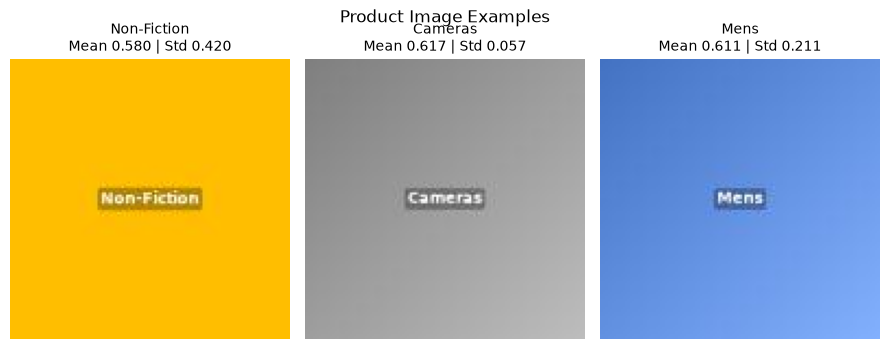

In [12]:
import matplotlib.image as mpimg

sample_rows = products.dropna(subset=["image_mean"]).sample(n=3, random_state=RANDOM_SEED)

fig, axes = plt.subplots(1, len(sample_rows), figsize=(9, 3.6), squeeze=False)

for ax, (_, row) in zip(axes[0], sample_rows.iterrows()):
    img = mpimg.imread(str(analyzer.image_path(row["prod_cat_code"], row["prod_subcat_code"])))
    ax.imshow(img)
    ax.set_title(
        f"{row['prod_subcat']}\nMean {row['image_mean']:.3f} | Std {row['image_std']:.3f}",
        fontsize=10,
    )
    ax.axis("off")

fig.suptitle("Product Image Examples")
fig.tight_layout()
plt.show()

## 6. 인구통계 피처 분석

고객의 성별(`Gender`)과 도시 코드(`city_code`)별 구매 패턴을 분석한다.

- `Gender`: 성별에 따른 구매 빈도와 평균 거래 금액 비교
- `city_code`: 지역별 고객 분포와 평균 구매 금액 비교

고객 1인당 통계를 계산해 거래 수가 많은 고객의 중복 반영을 막는다.

In [13]:
gender_stats = (
    df.groupby(["customer_id", "Gender"])
    .agg(total_spent=("total_amt", "sum"), purchase_days=("tran_date", "nunique"))
    .reset_index()
    .groupby("Gender")
    .agg(
        customer_count=("customer_id", "count"),
        avg_total_spent=("total_spent", "mean"),
        avg_purchase_days=("purchase_days", "mean"),
    )
    .round(2)
)

display(gender_stats)

,customer_count,avg_total_spent,avg_purchase_days
Gender,,,
F,147,10249.61,3.92
M,153,9706.13,3.97


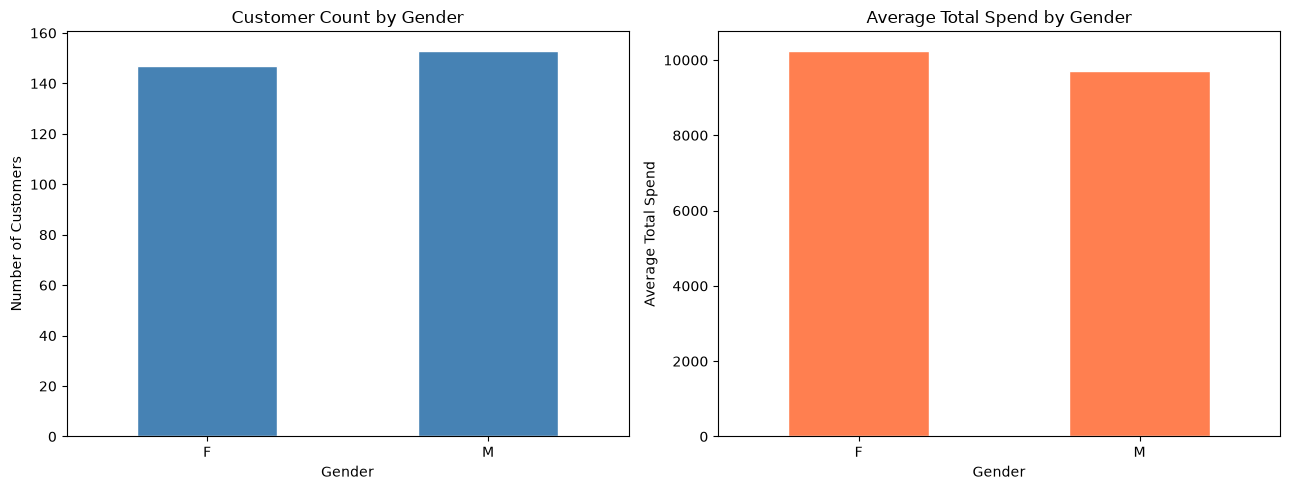

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

gender_stats["customer_count"].plot(
    kind="bar", ax=axes[0], color="steelblue", edgecolor="white"
)
axes[0].set_title("Customer Count by Gender")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Number of Customers")
axes[0].tick_params(axis="x", rotation=0)

gender_stats["avg_total_spent"].plot(
    kind="bar", ax=axes[1], color="coral", edgecolor="white"
)
axes[1].set_title("Average Total Spend by Gender")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Average Total Spend")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

## 7. 통계 분석

거래 금액, 수량, 상품명 길이, 이미지 평균·표준편차의 분포를 확인하고,
변수 간 피어슨 상관계수를 계산한다.

거래 데이터를 기준으로 계산하므로 여러 번 구매된 상품은 반복 반영된다.
상관관계는 인과관계를 의미하지 않는다.

In [15]:
display(
    analyzer.summarize(
        df, ["total_amt", "Qty", "product_name_length", "image_mean", "image_std"]
    ).round(4)
)

,total_amt,Qty,product_name_length,image_mean,image_std
count,1188.0000,1188.000,1188.0000,1188.0000,1188.0000
mean,2518.2922,3.021,7.0017,0.5453,0.2079
std,1915.1927,1.415,3.8000,0.0653,0.1272
min,78.4550,1.000,3.0000,0.4015,0.0351
25%,1013.5612,2.000,4.0000,0.4950,0.1629
50%,1971.8725,3.000,6.0000,0.5375,0.1691
75%,3587.6588,4.000,8.0000,0.6106,0.2110
max,8287.5000,5.000,19.0000,0.6392,0.4203


In [16]:
print(
    "거래 금액과 이미지 평균의 상관계수:",
    round(df["total_amt"].corr(df["image_mean"]), 4),
)
print(
    "거래 금액과 이미지 표준편차의 상관계수:",
    round(df["total_amt"].corr(df["image_std"]), 4),
)

거래 금액과 이미지 평균의 상관계수: -0.0108
거래 금액과 이미지 표준편차의 상관계수: 0.0107


거래 금액과 이미지 통계의 상관계수는 모두 0에 가깝다. 합성 이미지는 상품 코드 기반 고정 시드로 무작위 생성되어 가격 정보를 담지 않으므로, 두 상관계수가 0 근방에 형성되는 것은 예상된 결과다. 실제 상품 이미지를 사용한다면 색상·밝기와 가격대 사이의 관계를 탐색할 수 있다. 거래 금액과 수량의 양의 상관(0.6 이상)은 대량 구매가 고금액 거래로 이어짐을 나타낸다.

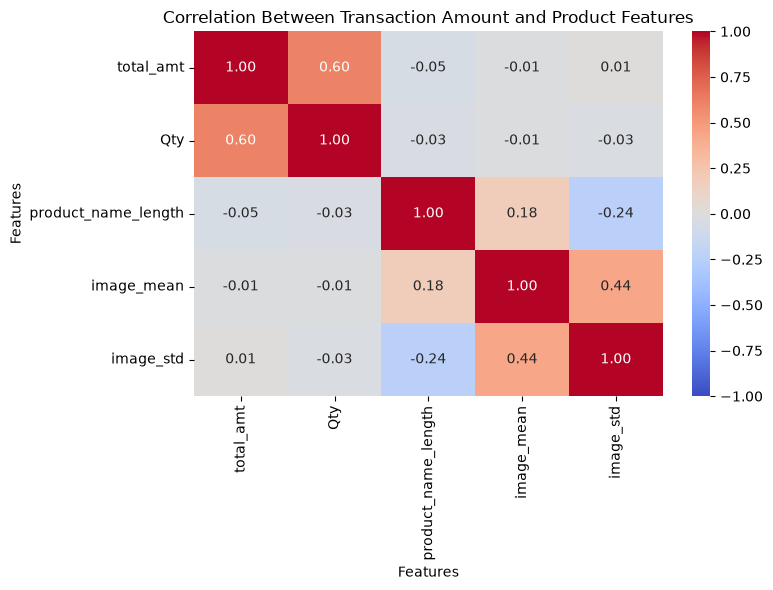

In [17]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df[["total_amt", "Qty", "product_name_length", "image_mean", "image_std"]].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
)

plt.title("Correlation Between Transaction Amount and Product Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

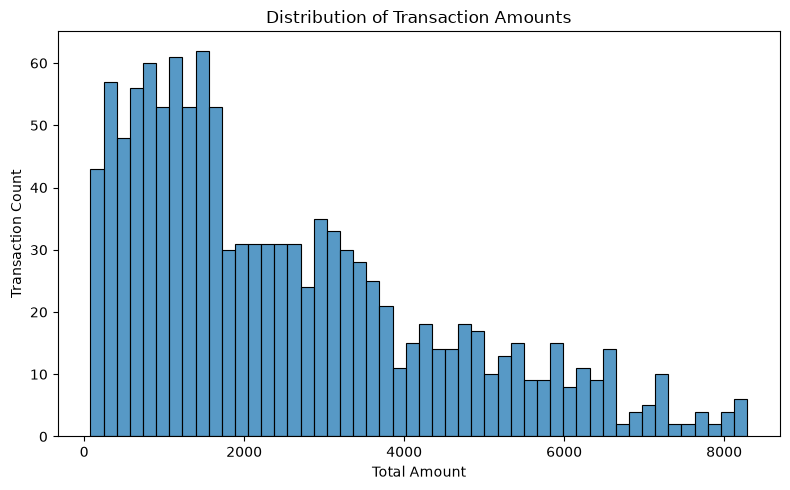

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="total_amt", bins=50)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Total Amount")
plt.ylabel("Transaction Count")
plt.tight_layout()
plt.show()

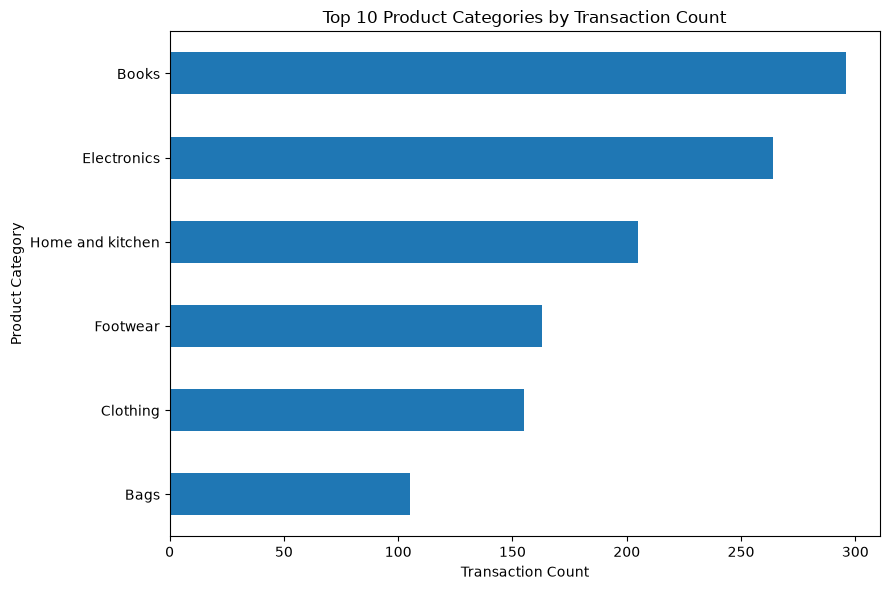

In [19]:
df["prod_cat"].value_counts().head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 6),
)

plt.title("Top 10 Product Categories by Transaction Count")
plt.xlabel("Transaction Count")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

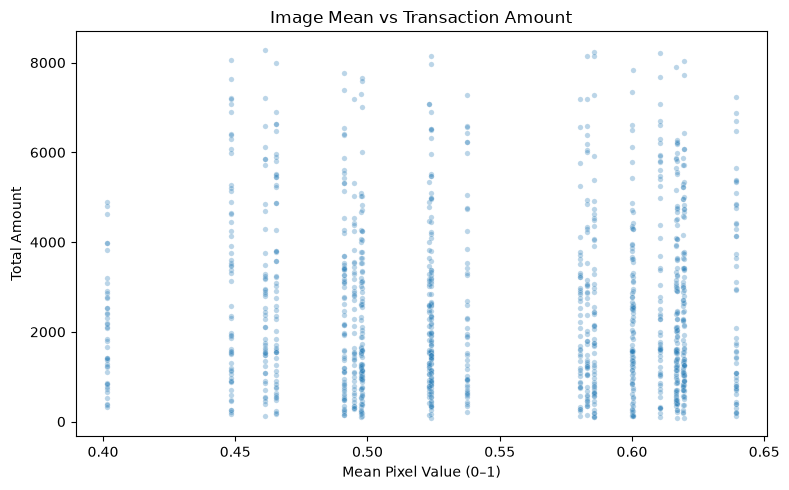

In [20]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="image_mean",
    y="total_amt",
    alpha=0.3,
    s=15,
)

plt.title("Image Mean vs Transaction Amount")
plt.xlabel("Mean Pixel Value (0–1)")
plt.ylabel("Total Amount")
plt.tight_layout()
plt.show()

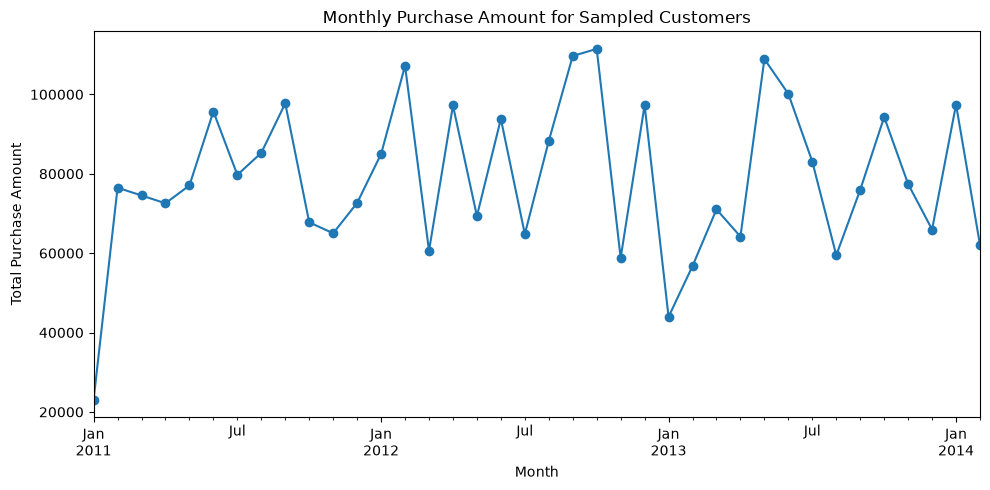

In [21]:
df.resample(
    "MS",
    on="tran_date",
)["total_amt"].sum().plot(
    figsize=(10, 5),
    marker="o",
)

plt.title("Monthly Purchase Amount for Sampled Customers")
plt.xlabel("Month")
plt.ylabel("Total Purchase Amount")
plt.tight_layout()
plt.show()

## 8. RFM 고객 분석

분석 기준일은 표본 거래 데이터의 최종 거래일로 설정한다.

- Recency: 분석 기준일부터 마지막 구매일까지의 경과 일수
- Frequency: 고객별 서로 다른 구매 날짜 수
- Monetary: 고객별 거래 금액의 합계

이상치 후보와 동일한 거래 행도 유지한다.
고가 구매 및 대량 구매가 고객 구매금액에 반영되도록 한다.

In [22]:
reference_date = df["tran_date"].max()

print("분석 기준일:", reference_date)

분석 기준일: 2014-02-19 00:00:00


In [23]:
rfm = analyzer.calculate_rfm(df, reference_date=reference_date)

print("RFM 고객 수:", len(rfm))
display(rfm.head())

RFM 고객 수: 300


,recency,frequency,monetary
customer_id,,,
266805,54,1,4623.320
266814,340,5,12167.155
266822,129,8,24577.410
266836,739,4,11082.045
266901,88,4,8327.280


In [24]:
display(rfm.describe().round(2))

,recency,frequency,monetary
count,300.00,300.00,300.00
mean,259.63,3.95,9972.44
std,232.31,1.89,6074.66
min,0.00,1.00,110.50
25%,80.75,3.00,5300.68
50%,197.00,4.00,8873.15
75%,373.00,5.00,13617.19
max,1074.00,10.00,29597.42


## 9. RFM 점수와 고객 세분화

각 지표의 상대적 순위를 기준으로 1~5점을 부여한다.

- Recency: 경과 일수가 짧을수록 높은 점수
- Frequency: 구매 날짜 수가 많을수록 높은 점수
- Monetary: 구매금액 합계가 클수록 높은 점수

동일한 값에는 동일한 점수를 부여한다.
따라서 점수별 고객 수가 정확히 같지는 않을 수 있다.

In [25]:
rfm["r_score"] = np.ceil(
    rfm["recency"].rank(ascending=False, pct=True) * 5
).astype(int)

rfm["f_score"] = np.ceil(
    rfm["frequency"].rank(pct=True) * 5
).astype(int)

rfm["m_score"] = np.ceil(
    rfm["monetary"].rank(pct=True) * 5
).astype(int)

display(rfm.head())

,recency,frequency,monetary,r_score,f_score,m_score
customer_id,,,,,,
266805,54,1,4623.320,5,1,2
266814,340,5,12167.155,2,4,4
266822,129,8,24577.410,4,5,5
266836,739,4,11082.045,1,3,4
266901,88,4,8327.280,4,3,3


### RFM 세그먼트 분류 기준

고객별 최근성(R), 구매 빈도(F), 구매 금액(M)의 상대 순위를 1점부터 5점으로 환산한다. 마지막 구매가 최근일수록 R, 구매일 수가 많을수록 F, 거래 금액 합계가 클수록 M 점수가 높다. 순위 비율에 5를 곱해 올림하므로 4점과 5점은 상위 약 40%에 해당한다. 동점에는 평균 순위를 적용하므로 실제 비율은 달라질 수 있다.

| 우선순위 | 세그먼트 | 분류 조건 | 기준을 둔 이유 |
| --- | --- | --- | --- |
| 1 | VIP | `R ≥ 4`, `F ≥ 4`, `M ≥ 4` | 최근에 구매했고, 자주 구매하고, 구매 금액도 높은 고객 |
| 2 | Loyal | `R ≥ 3`, `F ≥ 4` | 최근성 기준을 완화하고 반복 구매를 중심으로 분류 |
| 3 | New | `R ≥ 4`, `frequency == 1` | 최근에 구매했고 관측 기간에 구매한 날짜가 하루인 고객 |
| 4 | At Risk | `R ≤ 2` | 마지막 구매가 표본 내에서 상대적으로 오래된 고객 |
| 5 | Regular | 앞선 조건 중 충족한 조건이 없음 | 기본 분류 |

In [26]:
rfm["segment"] = np.select(
    [
        (rfm["r_score"] >= 4)
        & (rfm["f_score"] >= 4)
        & (rfm["m_score"] >= 4),

        (rfm["r_score"] >= 3)
        & (rfm["f_score"] >= 4),

        (rfm["r_score"] >= 4)
        & (rfm["frequency"] == 1),

        rfm["r_score"] <= 2,
    ],
    [
        "VIP",
        "Loyal",
        "New",
        "At Risk",
    ],
    default="Regular",
)

display(rfm["segment"].value_counts())
print("세그먼트 수:", rfm["segment"].nunique())

segment
At Risk    120
Regular     94
VIP         50
Loyal       31
New          5
Name: count, dtype: int64

세그먼트 수: 5


In [27]:
seg_summary = (
    rfm.groupby("segment")
    .agg(
        customer_count=("monetary", "size"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean"),
        total_monetary=("monetary", "sum"),
    )
    .round(4)
)

seg_summary["monetary_pct"] = (
    seg_summary["total_monetary"] / seg_summary["total_monetary"].sum() * 100
).round(2)

display(seg_summary)

,customer_count,avg_recency,avg_frequency,avg_monetary,total_monetary,monetary_pct
segment,,,,,,
At Risk,120,488.4583,3.1417,7569.2132,908305.580,30.36
Loyal,31,148.0000,5.8710,12770.3068,395879.510,13.23
New,5,63.8000,1.0000,2572.8820,12864.410,0.43
Regular,94,122.4149,3.1915,8522.3595,801101.795,26.78
VIP,50,57.2000,6.4000,17471.5970,873579.850,29.20


## 10. 비즈니스 인사이트

### 분석 범위

고정 시드(42)로 뽑은 고객 300명의 거래를 분석했다. RFM 기준일은 표본의 마지막 거래일이다. Frequency는 서로 다른 구매 날짜 수이고, Monetary는 거래 금액의 합계다. 금액 비중은 세그먼트별 합계를 기준으로 계산했다. 이미지 피처는 상품 코드 기반 고정 시드로 생성한 합성 배열에서 추출했으며, 거래 금액과의 상관계수가 0 근방(0.05 이하)으로 나타난 것은 무작위 생성 특성에 기인한다.

### 1. At Risk 고객 재활성화 우선 검토

**근거.** At Risk는 마지막 구매가 상대적으로 오래된 고객군으로, 구매금액 비중이 가장 높다.
**실행.** 과거 구매금액과 평소 구매 간격을 함께 보고 연락 대상을 좁혀 재구매를 유도한다.
**검증.** 선별된 고객의 후속 구매율을 동일 기간 연락하지 않은 대조군과 비교한다.

### 2. VIP 고객 유지

**근거.** VIP는 세그먼트 중 평균 구매일 수와 평균 구매금액이 모두 가장 높다.
**실행.** 선호 카테고리의 신상품이나 프로모션을 안내해 재구매를 유도한다.
**검증.** VIP 내 대조군을 두고 동일 기간의 재구매율과 고객당 구매금액을 비교한다.

### 3. Loyal과 Regular의 다음 구매 유도

**근거.** Loyal의 평균 구매일 수는 Regular보다 많으나, 마지막 구매 경과일도 길다.
**실행.** Loyal에는 반복 구매한 카테고리의 후속 상품을, Regular에는 관심 상품과 함께 구매할 만한 상품을 안내해 구매일 수 증가를 목표로 한다.
**검증.** 세그먼트마다 대조군을 두고 후속 구매일 수를 비교한다.